# Quadratic Root Certificate

## tl;dr
Exact rational enclosures recover the simple price roots and the double fold root. The guarantee is **only** for each quadratic equation; the economic regime inequalities remain a separate model check.

## Context & Methods

A liquidation regime reduces the scalar price equation to $a q^2+b q+c=0$. For rational coefficients, $\Delta=b^2-4ac$ is exact. We bound $\sqrt{\Delta}$ between adjacent rationals with denominator $10^d$ using integer square root. Substitution into the quadratic formula gives rational intervals.

### Key assumptions
Degree exactly two; rational coefficients; declared regime domains supplied externally. No claim of a certified payment vector, global equilibrium completeness, welfare, or empirical identification.

In [1]:
from pathlib import Path
import json, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
cert = pd.read_csv(ROOT/'results/certificates.csv')
validation = pd.read_csv(ROOT/'results/validation.csv')
stability = pd.read_csv(ROOT/'results/stability.csv')
costs = pd.read_csv(ROOT/'results/costs.csv')
meta = json.loads((ROOT/'results/metadata.json').read_text())
print({'seed': meta['seed'], 'random_cases': meta['random_cases'], 'max_float_error': meta['max_float_midpoint_error']})

{'seed': 20261021, 'random_cases': 100, 'max_float_error': 1.432187701766452e-14}


## Results

The table distinguishes every polynomial root from roots that also lie wholly inside the declared economic regime interval.

In [2]:
cert[['case','midpoint','width','multiplicity','inside_declared_domain']]

,case,midpoint,width,multiplicity,inside_declared_domain
0,fire_sale,0.200000,0.000000e+00,1,True
1,fire_sale,0.800000,0.000000e+00,1,True
2,fold_double,0.500000,0.000000e+00,2,True
3,coupled_interior,0.144405,5.000000e-31,1,True
4,coupled_interior,0.775595,5.000000e-31,1,False
5,coupled_high,0.174424,5.000000e-31,1,False
6,coupled_high,0.825576,5.000000e-31,1,True


In [3]:
assert cert.query("case == 'fold_double'").iloc[0].multiplicity == 2
assert validation.certificate_width_max.max() <= 1e-24
print('100/100 random rational-root cases enclosed; max float midpoint error:', validation.float_error.max())

100/100 random rational-root cases enclosed; max float midpoint error: 1.4321877017664523e-14


### Stability and computational cost

Widths are mathematical enclosures, not confidence intervals. Timings compare different guarantees and do not imply general solver superiority.

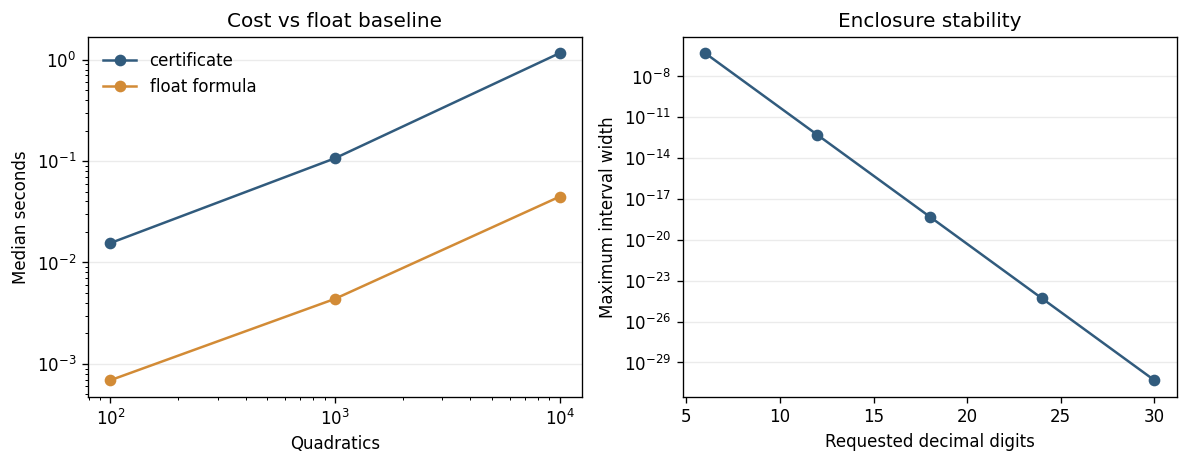

In [4]:
palette={'certificate':'#315b7d','float_formula':'#d28b36'}
fig, axes = plt.subplots(1,2,figsize=(10,4))
for method, group in costs.groupby('method'):
    axes[0].plot(group.cases, group.median_seconds, marker='o', label=method.replace('_',' '), color=palette[method])
axes[0].set(xscale='log', yscale='log', xlabel='Quadratics', ylabel='Median seconds', title='Cost vs float baseline')
axes[0].legend(frameon=False)
axes[1].plot(stability.decimal_digits, stability.max_width, marker='o', color='#315b7d')
axes[1].set(yscale='log', xlabel='Requested decimal digits', ylabel='Maximum interval width', title='Enclosure stability')
for ax in axes: ax.grid(axis='y', alpha=.25)
fig.tight_layout(); plt.show()

## Negative ablation

A 0.01 sign-change grid reports zero crossings for $(q-0.5)^2$, while the exact discriminant certifies the root $q=0.5$ with multiplicity two. This refutes the adequacy of that baseline for folds, not the usefulness of grids for exploration.

In [5]:
ablation = pd.read_csv(ROOT/'results/ablations.csv')
ablation
assert int(ablation.sign_change_hits.iloc[0]) == 0 and int(ablation.certified_roots.iloc[0]) == 1

## Takeaways

The MVP closes a numerical audit gap for quadratic price-regime equations and exposes a measurable cost premium. A root inside a declared scalar interval is still not proof that all bank-level inequalities, payments, or equilibrium assumptions hold.